In [1]:
import os
import sys
import torch
import numpy as np
import pandas as pd
import argparse
import torchvision.transforms as T
from data_utils import *
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
import pickle
from PIL import Image
os.chdir("..")
from src.utils import *

In [ ]:
# subject = 5
# create_whole_region_unnormalized(subject = subject, include_heldout=True)
# create_whole_region_unnormalized(subject = subject, include_heldout=False)
# create_whole_region_normalized(subject = subject, include_heldout=False)
# create_whole_region_normalized(subject = subject, include_heldout=True)
for subject in tqdm([1,2,5,7]):
    create_whole_region_imagery_unnormalized(subject = subject)
    create_whole_region_imagery_normalized(subject = subject)
    create_whole_region_imagery_unnormalized(subject = subject, mask=False)
    create_whole_region_imagery_normalized(subject = subject, mask=False)
for subject in tqdm(range(1,9)):
    create_whole_region_imagery_unnormalized(subject = subject)
    create_whole_region_imagery_normalized(subject = subject)
    create_whole_region_imagery_unnormalized(subject = subject, mask=False)
    create_whole_region_imagery_normalized(subject = subject, mask=False)
    create_whole_region_imagery_unnormalized(subject = subject, GLMdenoise=False)
    create_whole_region_imagery_normalized(subject = subject, GLMdenoise=False)
    create_whole_region_imagery_unnormalized(subject = subject, mask=False, GLMdenoise=False)
    create_whole_region_imagery_normalized(subject = subject, mask=False, GLMdenoise=False)
# process_masks(subject=subject)
# process_data(vector="c", include_heldout=True, subjects=[1,2,5,7])
# process_data(vector="images", include_heldout=True, subjects=[1,2,5,7])

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]


FileNotFoundError: No such file or no access: 'data/nsddata/ppdata/subj00/func1pt8mm/roi/nsdgeneral.nii.gz'

torch.Size([1000, 3, 512, 512]) torch.Size([1000, 257, 768])


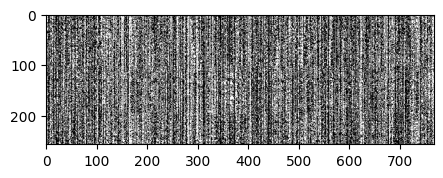

In [ ]:
from torchvision import transforms
path = "data/preprocessed_data/subject1/"
blurry = torch.load(f"{path}mindeye_40_blurry_imgs.pt")
recons = torch.load(f"{path}mindeye_40_clip.pt")
print(blurry.shape, recons.shape)
blurry_0 = blurry[0]
recons_0 = recons[0]
blurry_0_pil = transforms.ToPILImage()(blurry_0)
recons_0_pil = transforms.ToPILImage()(recons_0)
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
    
axes.imshow(recons_0_pil, cmap='gray')

/export/raid1/home/kneel027/miniconda3/envs/SS/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: '/export/raid1/home/kneel027/miniconda3/envs/SS/lib/python3.10/site-packages/torchvision/image.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
/export/raid1/home/kneel027/miniconda3/envs/SS/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loading images
loaded images!!!


  0%|          | 0/30000 [00:00<?, ?it/s]

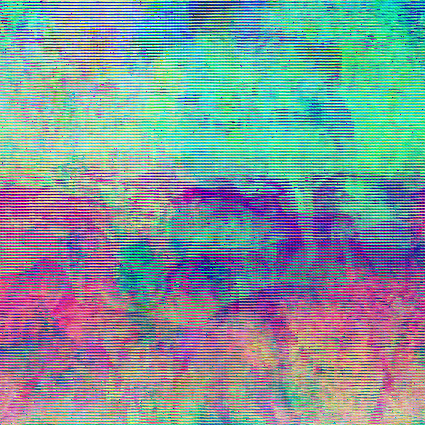

  0%|          | 0/30000 [00:02<?, ?it/s]


TypeError: ToTensor.__init__() takes 1 positional argument but 2 were given

In [1]:
import os
import sys
import torch
import numpy as np
import pandas as pd
import argparse
import torchvision.transforms as T
import pickle
from PIL import Image
from IPython.display import display
from tqdm import tqdm
os.chdir("..")
for subject in range(1,9):
    print("loading images")
    y = torch.load("data/preprocessed_data/subject{}/images.pt".format(subject)).requires_grad_(False).to("cpu")
    print("loaded images!!!")
    y_tensor = torch.zeros((y.shape[0], 3, 425, 425))
    for i in tqdm(range(y.shape[0])):
        pil_im = Image.fromarray(y[i].reshape((425, 425, 3)).numpy().astype(np.uint8))
        # Display the PIL image
        # display(pil_im)
        tensor_im = T.ToTensor()(pil_im)
        y_tensor[i] = tensor_im
    torch.save(y_tensor, "data/preprocessed_data/subject{}/images_tensor.pt".format(subject))

In [ ]:
y_tensor = torch.zeros((y.shape[0], 3, 425, 425))
for i in tqdm(range(y.shape[0])):
    pil_im = Image.fromarray(y[i].reshape((425, 425, 3)).numpy().astype(np.uint8))
    # Display the PIL image
    # display(pil_im)
    tensor_im = T.ToTensor()(pil_im)
    y_tensor[i] = tensor_im
torch.save(y_tensor, "data/preprocessed_data/subject{}/images_tensor.pt".format(subject))
    
for subject in range(2,9):
    print("loading images")
    y = torch.load("data/preprocessed_data/subject{}/images.pt".format(subject)).requires_grad_(False).to("cpu")
    print("loaded images!!!")
    y_tensor = torch.zeros((y.shape[0], 3, 425, 425))
    for i in tqdm(range(y.shape[0])):
        pil_im = Image.fromarray(y[i].reshape((425, 425, 3)).numpy().astype(np.uint8))
        # Display the PIL image
        # display(pil_im)
        tensor_im = T.ToTensor()(pil_im)
        y_tensor[i] = tensor_im
    torch.save(y_tensor, "data/preprocessed_data/subject{}/images_tensor.pt".format(subject))